In [2]:
import pandas as pd

df = pd.read_csv('Text_classification.csv')
print(df.head())


  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


digunakan untuk memuat dan melihat struktur awal data dari sebuah file CSV. Perintah import pandas as pd berfungsi untuk memanggil pustaka Pandas, pd.read_csv('Text_classification.csv') membaca file dataset teks dan menyimpannya ke dalam variabel DataFrame (df), sedangkan print(df.head()) menampilkan lima baris pertama data ke layar

In [3]:
#Download resource NLTK yang diperlukan
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

# Import library untuk preprocessing
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Inisialisasi Lemmatizer
lemmatizer = WordNetLemmatizer()

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower() # Ubah menjadi Lowercase
    text = re.sub(r'\d+', '', text) # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation)) # Hapus tanda baca
    words = word_tokenize(text) # Tokenisasi
    words = [word for word in words if word not in stopwords.words('english')] # Hapus stopwords
    words = [lemmatizer.lemmatize(word) for word in words] # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['Message'].apply(clean_text)

# Cek hasil preprocessing
print("\nHasil Preprocessing:\n", df[['Message', 'clean_text']].head())

[nltk_data] Downloading package punkt_tab to C:\Users\MSI MODERN
[nltk_data]     14\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt to C:\Users\MSI MODERN
[nltk_data]     14\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to C:\Users\MSI MODERN
[nltk_data]     14\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to C:\Users\MSI MODERN
[nltk_data]     14\AppData\Roaming\nltk_data...



Hasil Preprocessing:
                                              Message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


berfungsi untuk menjalankan semua tahapan text preprocessing sebelum data teks diolah ke dalam model klasifikasi. Proses diawali dengan mengunduh dan mengimpor pustaka NLTK beserta modul pendukung seperti regex, string, stopwords, dan lemmatizer. Selanjutnya, dibuat sebuah fungsi clean_text yang bertugas mengubah seluruh huruf menjadi kecil, menghapus angka serta tanda baca, memecah kalimat menjadi token kata, menyaring kata-kata umum yang tidak penting (stopwords), hingga mengubah setiap kata ke bentuk dasarnya (lemmatization). Terakhir, fungsi tersebut diterapkan ke seluruh baris data pada kolom Message untuk disimpan ke dalam kolom baru bernama clean_text

In [4]:
# Ubah Label dari 'ham'/'spam' menjadi 0/1
df['Category'] = df['Category'].map({'ham': 0, 'spam': 1})

# Cek jumlah masing-masing kelas
print(df['Category'].value_counts())

Category
0    4825
1     747
Name: count, dtype: int64


digunakan untuk mengubah format label kelas pada dataset teks agar dapat diproses oleh model machine learning. Baris pertama (df['Category'].map(...)) berfungsi untuk mengubah label kategori teks yang awalnya berupa teks string 'ham' menjadi angka 0 dan 'spam' menjadi angka 1. baris berikutnya (print(...)) digunakan untuk menghitung dan menampilkan jumlah total data untuk masing-masing kelas tersebut untuk mengecek keseimbangan datanya

In [5]:
from sklearn.model_selection import train_test_split

# Pisahkan fitur dan Label
X = df['clean_text']
y = df['Category']

# Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

digunakan untuk membagi dataset menjadi training data testing data menggunakan fungsi train_test_split dari pustaka scikit-learn. Pada bagian awal, kolom clean_text ditetapkan sebagai fitur (X) dan kolom kategori ditetapkan sebagai label (y). Selanjutnya, data dibagi dengan komposisi 80% untuk pelatihan dan 20% untuk pengujian (test_size=0.2), dilengkapi dengan parameter random_state=42 agar hasil pembagian datanya konsisten setiap dijalankan, serta stratify=y untuk memastikan proporsi perbandingan kelas spam dan ham pada data latih dan data uji tetap seimbang.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Konversi teks menjadi fitur numerik menggunakan TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1,2), max_features=5000) # Menggunakan bigram
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("\nTF-IDF Shape (Train):", X_train_tfidf.shape)


TF-IDF Shape (Train): (4457, 5000)


Alat TfidfVectorizer diset supaya bisa mengenali kata satuan atau gabungan dua kata sekaligus (ngram_range=(1,2)), dan batasan kata pentingnya diambil maksimal 5.000 kata saja (max_features=5000).

untuk data latihan, komputer belajar sekaligus mengubah bentuk teksnya pakai perintah fit_transform.   Sedangkan untuk data ujian, bentuk teksnya cuma diubah saja pakai perintah transform tanpa belajar ulang supaya proses ujiannya tetap jujur dan tidak bocor kuncinya.

In [8]:
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi model Naïve Bayes
model = MultinomialNB(alpha=0.1)

# Train model
model.fit(X_train_tfidf, y_train)

# Prediksi hasil
y_pred = model.predict(X_test_tfidf)

Inisialisasi Model (MultinomialNB)untuk enyiapkan model klasifikasi Naïve Bayes (varian Multinomial yang cocok untuk data teks/hitung) dengan parameter penghalusan alpha=0.1 untuk membantu menangani kata-kata baru yang belum pernah muncul sebelumnya.

Pelatihan Model (model.fit)untuk memasukkan data latihan berupa teks yang sudah diubah menjadi angka (X_train_tfidf) beserta pasangannya yaitu label kategori (y_train), agar komputer dapat belajar mengenali pola kata-kata mana yang menandakan kategori tertentu.   Prediksi Hasil (model.predict) menggunakan model yang sudah pintar untuk menebak atau mengklasifikasikan kategori pada data pengujian (X_test_tfidf), lalu hasil tebakannya disimpan ke dalam variabel y_pred

In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.979372197309417

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



mengukur dan mengevaluasi seberapa baik performa model dalam menebak kategori pesan pada data pengujian dengan cara mengimpor fungsi evaluasi seperti accuracy_score, classification_report, dan confusion_matrix. Selanjutnya, program menghitung tingkat akurasi secara keseluruhan dengan membandingkan tebakan model (y_pred) terhadap label asli yang sebenarnya (y_test). kode ini mencetak laporan klasifikasi secara jelas yang mencakup metrik penting

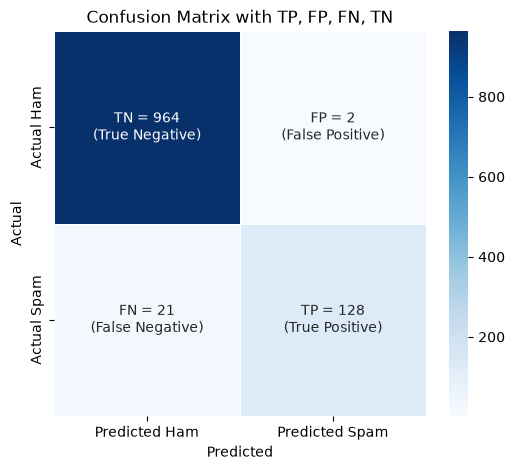

In [10]:
# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Hitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Definisi elemen dalam confusion matrix
TN, FP, FN, TP = conf_matrix.ravel()

# Buat dataframe confusion matrix
df_conf_matrix = pd.DataFrame(conf_matrix, index=['Actual Ham', 'Actual Spam'], columns=['Predicted Ham', 'Predicted Spam'])

# Label untuk TP, FP, FN, TN
labels = np.array([["TN = {}\n(True Negative)".format(TN), "FP = {}\n(False Positive)".format(FP)],
                   ["FN = {}\n(False Negative)".format(FN), "TP = {}\n(True Positive)".format(TP)]])

# Plot heatmap dengan keterangan
plt.figure(figsize=(6,5))
ax = sns.heatmap(df_conf_matrix, annot=labels, fmt='', cmap='Blues', linewidths=0.5, cbar=True)

# Tambahkan Label
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with TP, FP, FN, TN')
plt.show()

untuk memvisualisasikan hasil evaluasi model ke dalam bentuk grafik heatmap (peta panas) confusion matrix agar performa tebakan model lebih mudah dianalisis secara visual. 

program menghitung matriks perbandingan antara label asli dan tebakan menggunakan fungsi confusion_matrix, lalu memecahnya ke dalam komponen penting yaitu True Negative (TN), False Positive (FP), False Negative (FN), dan True Positive (TP). 

Data tersebut kemudian disusun rapi ke dalam tabel DataFrame Pandas dengan keterangan label kelas aktual dan prediksi. kemudian memanfaatkan pustaka seaborn dan matplotlib untuk menggambar grafik berwarna biru lengkap dengan label angka serta keterangan di setiap kotaknya agar hasil evaluasi model terlihat lebih jelas.

In [11]:
# Contoh teks baru
new_texts = ["Congratulations! You won a free trip to Bali.",
             "Hey, are you coming to the party tonight?"]

# Preprocess teks baru
new_texts_clean = [clean_text(text) for text in new_texts]

# Transformasi dengan TF-IDF
new_texts_tfidf = vectorizer.transform(new_texts_clean)

# Prediksi
predictions = model.predict(new_texts_tfidf)

# Output hasil prediksi
for text, label in zip(new_texts, predictions):
    print(f"\nMessage: {text} \nPredicted: {'Spam' if label == 1 else 'Ham'}")


Message: Congratulations! You won a free trip to Bali. 
Predicted: Spam

Message: Hey, are you coming to the party tonight? 
Predicted: Ham


digunakan untuk melakukan pengujian model menggunakan kalimat atau pesan baru di luar data latihan untuk melihat model mampu atau tidak menebak dengan benar. 

Pertama, program menyiapkan beberapa contoh teks baru yang ingin diuji, lalu membersihkannya menggunakan fungsi clean_text yang sama seperti sebelumnya. 

Setelah itu, teks yang sudah bersih diubah bentuknya menjadi angka menggunakan vectorizer.transform dan dimasukkan ke dalam model untuk ditebak kategorinya menggunakan model.predict. Terakhir, program mencetak kalimat asli beserta hasil tebakan model apakah termasuk kategori Spam atau Ham.